# Memory screen

This notebook is the specification and executable design audit for the optional initial memory screen. It reads the live JavaScript configuration, verifies the material, and exports PNG figures and CSV/JSON audit tables under `design_checks/figures/memory_screen/`.

| Stage | Participant flow |
|---|---|
| Entry | After instructions, comprehension, and Ready |
| Encoding | 20 green supply turns with a hidden drone and one distinct item per turn |
| Order test | 10 questions covering every studied identity once |
| Continue | At least 6 correct, with all 20 turns completed and 10 unique question records |
| End | A complete score below 6 ends before the four experimental blocks |
| Saving | Both outcomes reach the shared saving routine |

The initial turns are not labelled as practice, the cutoff is not displayed, and no correctness feedback is given. Their scores are excluded from main game totals and bonus calculations. Counts and cutoff follow the collaborator's protocol. The independent trajectory, images, and pair list are specified here.

## Controlled movement and supply distance

| Property | Configuration |
|---|---|
| Starting position | 50 percent of the rail, before turn 1 |
| Shift size | Exactly 9.05 percentage points on every turn |
| Direction balance | 10 left and 10 right shifts |
| Shift count | 20, including the move from the starting position to turn 1 |
| Drone visibility | Hidden throughout; visible-drone animation is disabled |
| Geometry | Fixed across participants and independent of item/test assignment |
| Target range | 31.90 to 68.10 percent, returning to 50 after turn 20 |
| Absolute supply offset | Exactly 2.957285 percentage points from the drone target |
| Supply direction balance | 10 left and 10 right landings, with 12 switches and no same-side run longer than two |
| Supply landing range | 34.857285 to 71.057285 percent, without clipping |
| Supply trajectory | Straight vertical fall from its fixed offset left or right of the drone |

The fixed step is calibrated to the midpoint of the main blocks’ realized mean absolute shifts on turns when the drone changes position, rounded to 0.01 percentage points. The absolute supply distance is the midpoint of the main blocks’ mean absolute rendered drone-to-supply distances. The current module is `ms-3.4.0-2026-10-25`, with geometry `ms-hidden-medium-v5`.

Equal drone displacement and equal absolute supply offset control variation in these two unsigned magnitudes. They do not establish constant psychological surprise. The drone remains hidden, so participants must estimate its position from supply landings, as in the main task. Direction is balanced without strict alternation, and no same-direction run exceeds two turns. The first movement is counted explicitly because 20 target positions alone contain only 19 adjacent differences.

Directional expectancy, reversals, supply landing prediction error, green feedback, motor familiarization, and memory-test experience can still influence encoding or transfer. Learning-rate responses to surprise and effects of context changes on order memory motivate these controls, without directly validating this screen. See [McGuire et al. 2014](https://pmc.ncbi.nlm.nih.gov/articles/PMC4437663/) and [DuBrow and Davachi 2013](https://pmc.ncbi.nlm.nih.gov/articles/PMC3902141/).

No latent regime change is programmed in this screen. The absolute supply offset is fixed throughout, with zero signed mean and an irregular, nonalternating direction sequence. A passing full route reminds participants that the drone remains hidden and movement and wind can differ between planets. The target positions are latent throughout; the retained animation-duration parameter is inactive while the drone is hidden.

## Setup and provenance

Use a Python environment with `design_checks/requirements-memory-screen.txt`, Node, and a Jupyter kernel for that environment. The notebook works from the repository root, `design_checks`, or `design_checks/notebooks`. Its Python helpers are in `design_checks/scripts/`. The authors' normative workbook is cached with attribution and its original SHA256 under `design_checks/references/memory_screen/`.

Routine execution reads the existing fixed runtime PNGs. Only deliberate asset revisions require macOS and `design_checks/scripts/render_memory_screen_items.py`.

```sh
python -m pip install -r design_checks/requirements-memory-screen.txt
python -m ipykernel install --user --name drone-design
python -m nbconvert --to notebook --execute --inplace design_checks/notebooks/06_memory_screen.ipynb --ExecutePreprocessor.kernel_name=drone-design
```

In [1]:
from pathlib import Path
import sys, platform
from IPython.display import display, Markdown
REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'index.html').exists() and (p / 'design_checks' / 'scripts').is_dir()), None)
if REPO_ROOT is None:
    raise RuntimeError('Open this notebook from within the DroneTask repository.')
sys.path.insert(0, str(REPO_ROOT / 'design_checks' / 'scripts'))
import memory_screen_checks as audit
import numpy as np
import pandas as pd
import matplotlib
import PIL
import scipy
DATA, NORMS, ITEMS = audit.load_design()
SCREEN = DATA['screen']
CHECKS = audit.check_all(DATA, ITEMS)
display(pd.DataFrame({'component':['module','series','items','reference item/test seed'],
    'value':[SCREEN['version'],SCREEN['series_version'],SCREEN['item_version'],SCREEN['seed']]}))
display(pd.DataFrame(DATA['source_hashes'].items(), columns=['live source','SHA256']))
print('Python', platform.python_version(), 'NumPy', np.__version__, 'pandas', pd.__version__,
      'matplotlib', matplotlib.__version__, 'Pillow', PIL.__version__, 'SciPy', scipy.__version__)
print(f'{len(CHECKS)} design checks passed')

(node:48837) Warning: The 'NO_COLOR' env is ignored due to the 'FORCE_COLOR' env being set.
(Use `node --trace-warnings ...` to show where the warning was created)


,component,value
0,module,ms-3.4.0-2026-10-25
1,series,ms-hidden-medium-v5
2,items,ms-objects-normed-g2
3,reference item/test seed,memory-screen-reference


,live source,SHA256
0,static/task/stimuli.js,0e27819e8522a80103affb6b60c2cec6998218dfb0b8d4...
1,static/task/preload.js,3927973fa87e1d22cd1883ffe904ae636b8d24c49737cd...
2,static/task/memory_screening/memory_screening.js,4e37812ac498fb7d7d94277827aeec7a29307b3dfc40de...
3,static/task/trial.js,0be5f2e1207b966d8b993dea775187d301002dd9fb02c6...
4,index.html,61f80d0612c09b98f25b1af46f4007799a4c2c54f3fe18...
5,design_checks/scripts/export_memory_screen.cjs,b8738a6f484db429d51d3eb29a37bfe25354a81475c0a5...
6,design_checks/scripts/memory_screen_checks.py,4b2f912ea5466afae6a17d651dc7aedd935c2991ddc65e...
7,design_checks/scripts/render_memory_screen_ite...,b6b4e33971057811f1ca3f0973ef397b3aeedcb020cec8...


Python 3.12.4 NumPy 2.5.4 pandas 3.1.0 matplotlib 3.11.2 Pillow 13.0.0 SciPy 1.18.1
37 design checks passed


## Trajectory comparison

The memory screen and four main conditions share the same rail-position scale and 50-turn horizontal axis. The screen finishes after turn 20. These are researcher views of the latent drone target, which participants never see. Its open circle at turn 0 marks the starting position; the connecting segment to turn 1 is the first of the 20 equal shifts. Dots show supply landings.

Source labels and realized magnitudes are distinguished throughout. Main arrays labelled high volatility have smaller realized mean shifts than those labelled low volatility. Main arrays labelled high stochasticity have smaller realized mean drone-to-supply distances than those labelled low stochasticity. Calibration uses the actual implementation under both reward/loss shift assignments and leaves the experimental arrays unchanged.

Movement calibration first computes the 49 adjacent target differences in each main block, then excludes the 34 stationary transitions and averages the 15 nonzero changes. It excludes the unknown initial baseline and between-block jumps. The trajectory table also retains the mean across all transitions as a separate diagnostic; that diagnostic is not the screening calibration. Supply distance means use all 50 trials. The supply-center bounds are parsed directly from `trial.js`; stochasticity comparisons apply those bounds before calculating the participant-visible distance. Raw scoring positions are retained as a separate diagnostic.

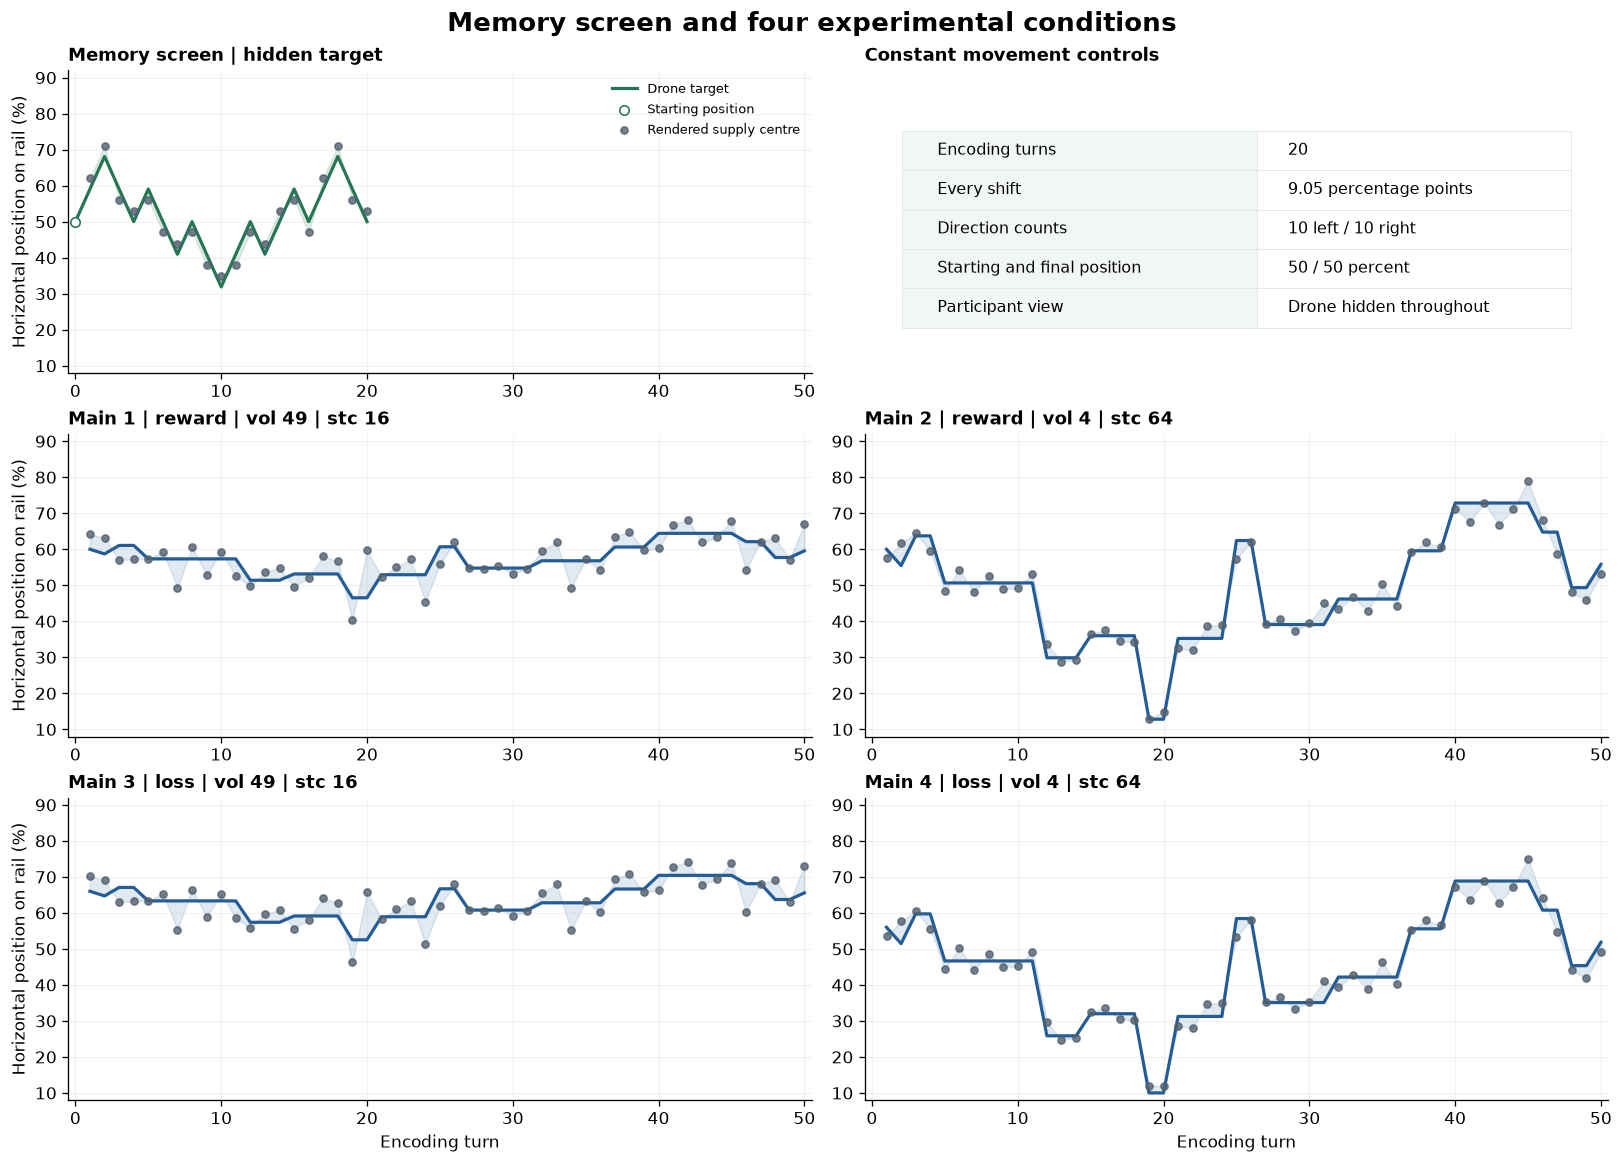

,series,trials,visible,baseline,drone_min,drone_max,n_shifts,n_left,n_right,mean_abs_step,max_step,residual_mean,residual_sd,mean_abs_distance_raw,mean_abs_distance_rendered,rendered_residual_sd,n_clipped_landings,max_abs_residual,programmed_regime_changes
0,Memory screen,20,False,50.0,31.900,68.100,20,10,10,9.050,9.050,0.000,2.957,2.957,2.957,2.957,0,2.957,0.0
1,Main 1 reward | loss shifted,50,False,NaN,46.517,64.419,49,7,8,1.225,7.766,0.196,4.261,3.388,3.388,4.261,0,13.155,NaN
2,Main 2 reward | loss shifted,50,False,NaN,12.810,72.844,49,7,8,4.340,27.184,-0.271,3.038,2.508,2.508,3.038,0,6.164,NaN
3,Main 3 loss | loss shifted,50,False,NaN,52.517,70.419,49,7,8,1.225,7.766,0.196,4.261,3.388,3.388,4.261,0,13.155,NaN
4,Main 4 loss | loss shifted,50,False,NaN,10.000,68.844,49,7,8,4.292,27.184,-0.298,3.025,2.481,2.546,3.055,2,6.164,NaN
5,Main 1 reward | reward shifted,50,False,NaN,52.517,70.419,49,7,8,1.225,7.766,0.196,4.261,3.388,3.388,4.261,0,13.155,NaN
6,Main 2 reward | reward shifted,50,False,NaN,10.000,68.844,49,7,8,4.292,27.184,-0.298,3.025,2.481,2.546,3.055,2,6.164,NaN
7,Main 3 loss | reward shifted,50,False,NaN,46.517,64.419,49,7,8,1.225,7.766,0.196,4.261,3.388,3.388,4.261,0,13.155,NaN
8,Main 4 loss | reward shifted,50,False,NaN,12.810,72.844,49,7,8,4.340,27.184,-0.271,3.038,2.508,2.508,3.038,0,6.164,NaN


In [2]:
audit.plot_trajectories(DATA)
METRICS = audit.trajectory_table(DATA)
display(METRICS.round(3))

## Movement and landing checks

Every signed drone shift is either −9.05 or +9.05 percentage points. Both directions occur ten times, including the baseline move. Every signed supply offset is either −2.957285 or +2.957285 percentage points, with ten landings on each side. Signs are not forced to alternate.

The figure separately shows target positions, signed drone shifts, signed supply offsets, and mean absolute rendered landing distance. Medium stochasticity is defined here by this distance. With equal balanced offsets, the screen’s SD also equals 2.957285 percentage points; this does not put its SD or variance midway between the main conditions. These series are selected without participant outcomes.

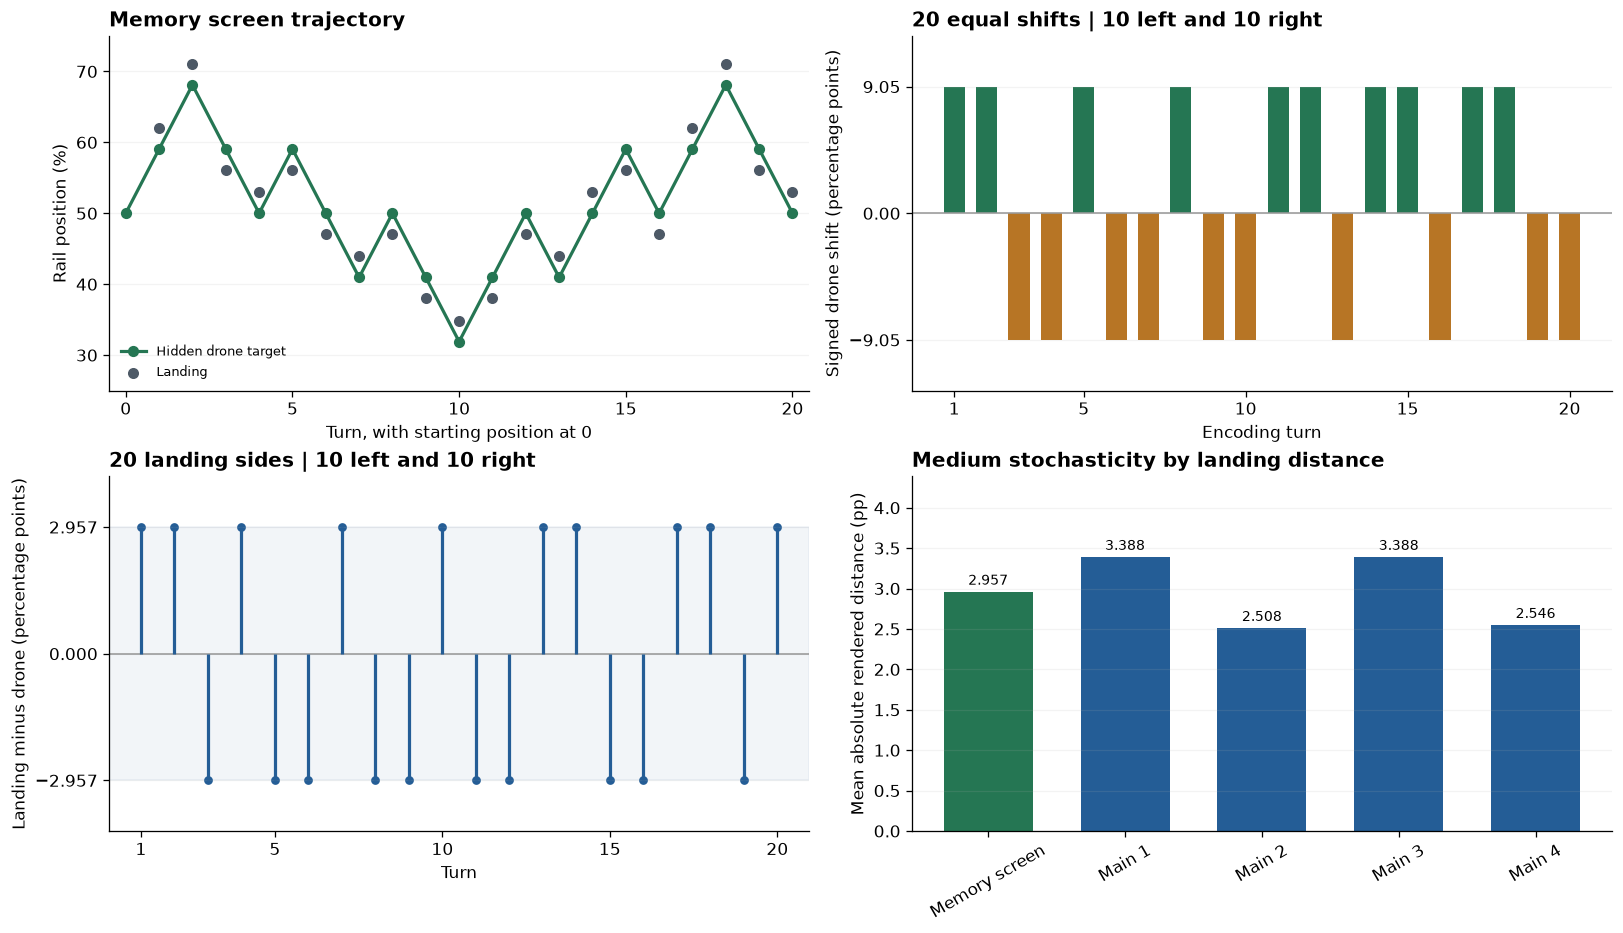

,turn,drone start,drone target,signed shift,direction,supply landing,landing offset
0,1,50.00,59.05,9.05,right,62.007285,2.957285
1,2,59.05,68.10,9.05,right,71.057285,2.957285
2,3,68.10,59.05,-9.05,left,56.092715,-2.957285
3,4,59.05,50.00,-9.05,left,52.957285,2.957285
4,5,50.00,59.05,9.05,right,56.092715,-2.957285
5,6,59.05,50.00,-9.05,left,47.042715,-2.957285
6,7,50.00,40.95,-9.05,left,43.907285,2.957285
7,8,40.95,50.00,9.05,right,47.042715,-2.957285
8,9,50.00,40.95,-9.05,left,37.992715,-2.957285
9,10,40.95,31.90,-9.05,left,34.857285,2.957285


Left shifts 10 Right shifts 10 Distinct absolute shift sizes [9.05 9.05]


In [3]:
audit.plot_noise(DATA)
x = np.asarray(SCREEN['drone_positions'])
starts = np.asarray(SCREEN['drone_start_positions'])
e = np.asarray(SCREEN['wind_offsets'])
display(pd.DataFrame({'turn':range(1,21), 'drone start':starts, 'drone target':x,
    'signed shift':x-starts, 'direction':['left' if d<0 else 'right' for d in x-starts],
    'supply landing':x+e, 'landing offset':e}))
print('Left shifts', sum(x<starts), 'Right shifts', sum(x>starts),
      'Distinct absolute shift sizes', np.unique(abs(x-starts)))

## Mean shift calibration

The reference is the mean absolute movement **when the main drone changes position**. Each 50-turn main block has 49 adjacent differences, of which 34 are zero. Calibration excludes those 34 stationary transitions and averages the 15 actual changes. The unknown first main-block baseline and all between-block jumps are excluded. All 20 screening shifts are included because its hidden target moves every turn from a known starting position.

| Source condition label | Mean movement on position changes, percentage points |
|---|---:|
| Low volatility, `vol=4` | 14.099333 |
| Memory screen | 9.050000 |
| High volatility, `vol=49` | 4.000600 |

The main arrays labelled low volatility have the larger realized movement on position changes. These source labels and experimental arrays are retained. Calibration uses the actual arrays, pooling reward and loss blocks within each volatility label. Both reward/loss shift assignments give the same group means.

The midpoint is 9.049967 percentage points, rounded to a fixed 9.05 step. It lies strictly between the two group means under both assignments and also between every individual block's mean on position changes. Means across all transitions remain available as diagnostics, but they do not set the screening step size. The following comparisons and counts are generated from the live configuration.

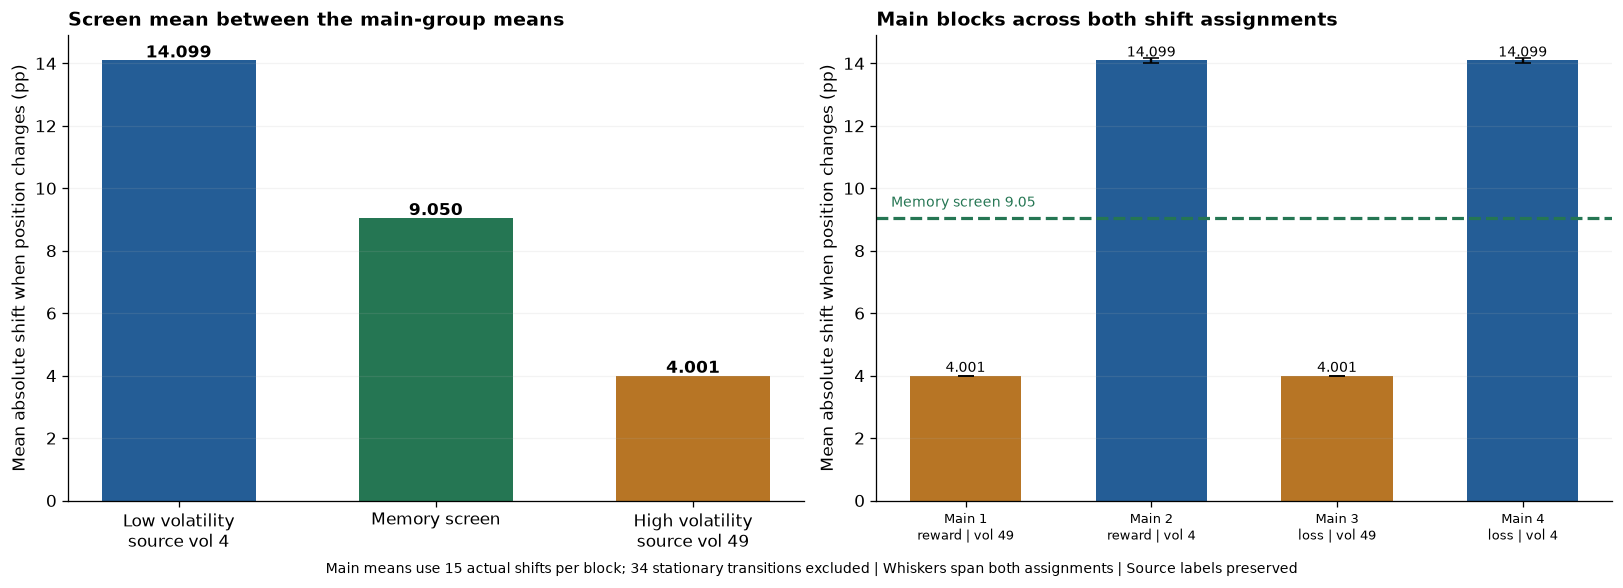

,assignment,low_vol_mean_nonzero_shift,high_vol_mean_nonzero_shift,midpoint,screen_mean_abs_shift,between_group_means
0,loss shifted,14.099333,4.0006,9.049967,9.05,True
1,reward shifted,14.099333,4.0006,9.049967,9.05,True


,assignment,condition,vol_param,n_transitions,n_zero_shifts,n_nonzero_shifts,mean_abs_shift,mean_nonzero_shift
0,loss shifted,1,49,49,34,15,1.224673,4.000600
1,loss shifted,2,4,49,34,15,4.340408,14.178667
2,loss shifted,3,49,49,34,15,1.224673,4.000600
3,loss shifted,4,4,49,34,15,4.291837,14.020000
4,reward shifted,1,49,49,34,15,1.224673,4.000600
5,reward shifted,2,4,49,34,15,4.291837,14.020000
6,reward shifted,3,49,49,34,15,1.224673,4.000600
7,reward shifted,4,4,49,34,15,4.340408,14.178667


In [4]:
audit.plot_shift_comparison(DATA)
display(audit.shift_calibration_table(DATA).round(6))
display(audit.main_shift_table(DATA)[[
    'assignment', 'condition', 'vol_param', 'n_transitions', 'n_zero_shifts',
    'n_nonzero_shifts', 'mean_abs_shift', 'mean_nonzero_shift']].round(6))

## Medium volatility and stochasticity

| Operational measure | Main reference | Memory screen |
|---|---|---|
| Volatility proxy | Mean absolute target shift over the 15 nonzero within-block changes, excluding 34 stationary transitions | Fixed 9.05 point shift, the rounded midpoint |
| Stochasticity proxy | Mean absolute target-to-rendered-supply distance over all 50 trials | Fixed 2.957285 point absolute offset, the midpoint |

The current source low-stochasticity label `stc=16` has mean rendered distance 3.387520 percentage points. The high-stochasticity label `stc=64` has mean rendered distance 2.527050. Their midpoint is 2.957285. Both reward/loss assignments give the same pooled means. The labels run opposite to realized distances; no main conditions are relabelled or changed.

The renderer clamps the supply-circle center to 12–88 percent. Two landings in the shifted `stc=64` block are clipped under each assignment. Before clipping, the high-stochasticity mean is 2.494590 and the raw/scoring midpoint is 2.941055. The participant-visible distance therefore uses the rendered midpoint. Screen landings are inside all bounds, so assigned and rendered distances agree.

The following figure, comparison tables, and assertions read live exported target arrays, landing arrays, direction sequence, and renderer bounds. They compare both medium measures with their main-block references. Midpoint mean absolute distance is not midpoint variance, SD, or subjective surprise.

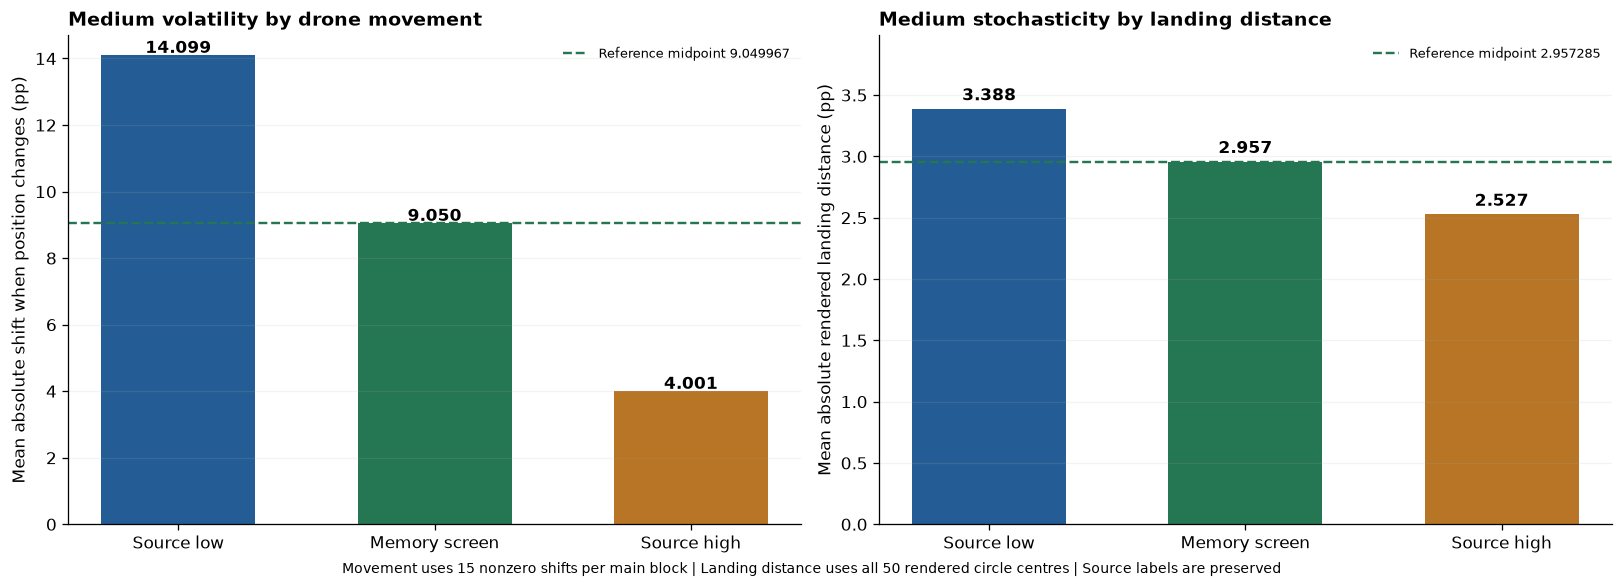

,quantity,measure,source_low_mean,screen_mean,source_high_mean,target_midpoint
0,Volatility,Mean absolute drone shift when position changes,14.099333,9.050000,4.00060,9.049967
1,Stochasticity,Mean absolute rendered landing distance,3.387520,2.957285,2.52705,2.957285


,assignment,low_stc_mean_abs_distance,high_stc_mean_abs_distance,midpoint,screen_mean_abs_distance,between_group_means,matches_midpoint
0,loss shifted,3.38752,2.52705,2.957285,2.957285,True,True
1,reward shifted,3.38752,2.52705,2.957285,2.957285,True,True


,mean_abs_distance_raw,mean_abs_distance_rendered
stc_param,,
16,3.38752,3.38752
64,2.49459,2.52705


,assignment,condition,stc_param,n_clipped_landings
3,loss shifted,4,64,2
5,reward shifted,2,64,2


Both medium levels verified from live main arrays and renderer bounds [12, 88]


In [5]:
audit.plot_medium_levels(DATA)
display(audit.medium_level_table(DATA).round(6))
display(audit.noise_calibration_table(DATA).round(6))
NOISE_REFERENCE = audit.stochasticity_reference_table(DATA)
display(NOISE_REFERENCE.groupby('stc_param')[
    ['mean_abs_distance_raw', 'mean_abs_distance_rendered']].mean().round(6))
display(NOISE_REFERENCE.loc[NOISE_REFERENCE.n_clipped_landings.gt(0),
    ['assignment', 'condition', 'stc_param', 'n_clipped_landings']])

# Independently reconstruct the operational means from the implementation export.
supply_bounds = DATA['renderer']['supply_bounds']
main_changes = [(block['vol_param'], np.abs(np.diff(block['drone'])))
    for variant in DATA['variants'] for block in variant['blocks']]
assert all(len(changes) == 49 and np.count_nonzero(changes == 0) == 34
           and np.count_nonzero(changes > 0) == 15
           for _, changes in main_changes)
main_movement = {vol: np.mean([
    changes[changes > 0].mean()
    for block_vol, changes in main_changes if block_vol == vol])
    for vol in [4, 49]}
main_distance = {stc: np.mean([
    np.abs(np.clip(np.asarray(block['landing']), *supply_bounds)
           - np.asarray(block['drone'])).mean()
    for variant in DATA['variants'] for block in variant['blocks']
    if block['stc_param'] == stc]) for stc in [16, 64]}
screen_moves = np.diff(np.r_[SCREEN['drone_initial_position'], SCREEN['drone_positions']])
screen_offsets = np.asarray(SCREEN['bag_positions']) - np.asarray(SCREEN['drone_positions'])
assert SCREEN['drone_step_metric'] == 'mean_absolute_nonzero_main_drone_shift'
assert np.isclose(np.abs(screen_moves).mean(), round(np.mean(list(main_movement.values())), 2))
assert np.allclose(np.abs(screen_offsets), np.mean(list(main_distance.values())), atol=1e-9)
assert np.count_nonzero(screen_offsets < 0) == np.count_nonzero(screen_offsets > 0) == 10
assert np.isclose(screen_offsets.mean(), 0)
assert np.any(np.sign(screen_offsets[1:]) == np.sign(screen_offsets[:-1]))
assert np.allclose(np.clip(SCREEN['bag_positions'], *supply_bounds), SCREEN['bag_positions'])
print('Both medium levels verified from live main arrays and renderer bounds', supply_bounds)

## Item selection

Twenty concrete object images have identifiable shape and component details. They exclude faces, animals, food, money, prizes, weapons, and explicit health content. Their exact identities and documented aliases do not overlap with any of the 200 experimental items, 13 tutorial identities, or real-game fallback emoji.

Selection uses the authors' [Emoji-SP database](https://osf.io/dtfjv/) from [Ferré et al. 2023](https://doi.org/10.3758/s13428-022-01893-6).

| Source variable | Selection rule |
|---|---|
| Valence | Mean 4 to 6 on the 1 to 9 scale |
| Arousal | Mean at most 4.8 on the 1 to 9 scale |
| Meaning clarity | Mean at least 3.5 on the 1 to 7 scale |
| Visual complexity | Mean 1.3 to 4.5 on the 1 to 7 scale |
| Ambiguous meaning | Source flag equals zero |

These are researcher-selected rules, not validated cutoffs for neutrality or memory. Emoji-SP used Facebook graphics and Spanish university students, whereas the task uses fixed Apple graphics. Familiarity rates communicative use, not object recognition. Aesthetic appeal and memory for these exact images have not been measured. Recognition, affect, appeal, and memorability still merit an independent pilot.

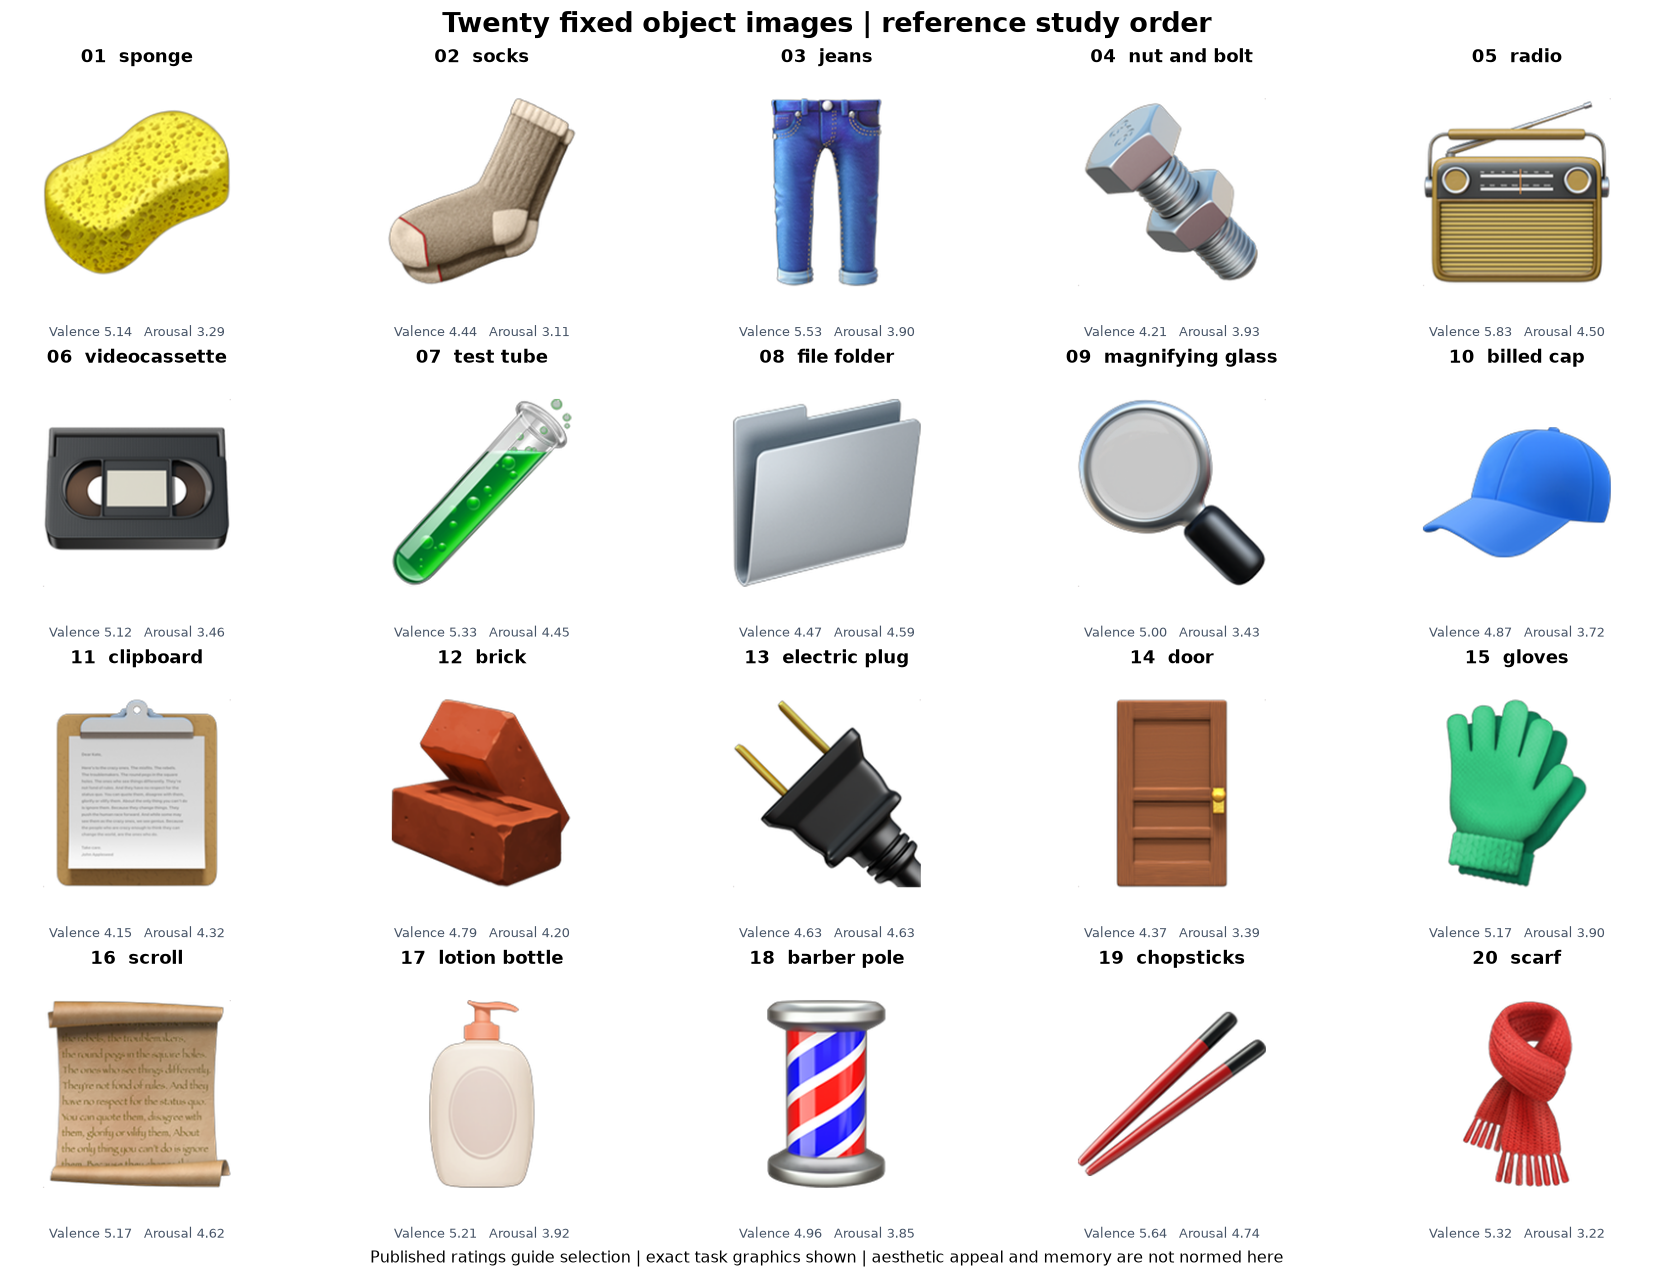

,concept,family,norm_id,detail,val,val_sd,aro,aro_sd,clar,vcomp,fam
0,sponge,household,994,porous yellow block and green scouring layer,5.143,1.508,3.286,1.607,4.933,1.933,1.690
1,socks,clothing,837,paired socks with contrasting heel and toe,4.444,1.311,3.107,1.853,6.967,2.208,1.458
2,jeans,clothing,833,"two denim legs, pockets and waistband",5.533,1.008,3.897,1.676,6.867,2.241,2.077
3,nut-and-bolt,hardware,967,threaded shaft and hexagonal nut,4.207,1.449,3.926,1.960,4.367,2.560,1.241
4,radio,electrical,881,"speaker grille, tuning scale and antenna",5.833,1.367,4.500,2.080,6.900,3.633,1.759
5,videocassette,media,906,"two reels, tape window and rectangular housing",5.125,1.393,3.462,2.370,6.286,2.375,1.720
6,test-tube,laboratory,971,"glass tube, colored liquid and small stopper",5.333,1.605,4.448,1.785,5.367,2.444,1.400
7,file-folder,stationery,944,tabbed folder with overlapping leaves,4.467,1.008,4.586,1.937,6.600,1.370,2.200
8,magnifying-glass,optical,907,"circular lens, rim and angled handle",5.000,1.569,3.429,2.133,5.867,1.542,2.400
9,billed-cap,clothing,862,curved visor and segmented crown,4.867,1.137,3.724,1.962,5.690,2.000,1.846


In [6]:
audit.plot_items(ITEMS)
display(ITEMS[['concept','family','norm_id','detail','val','val_sd','aro','aro_sd','clar','vcomp','fam']].round(3))

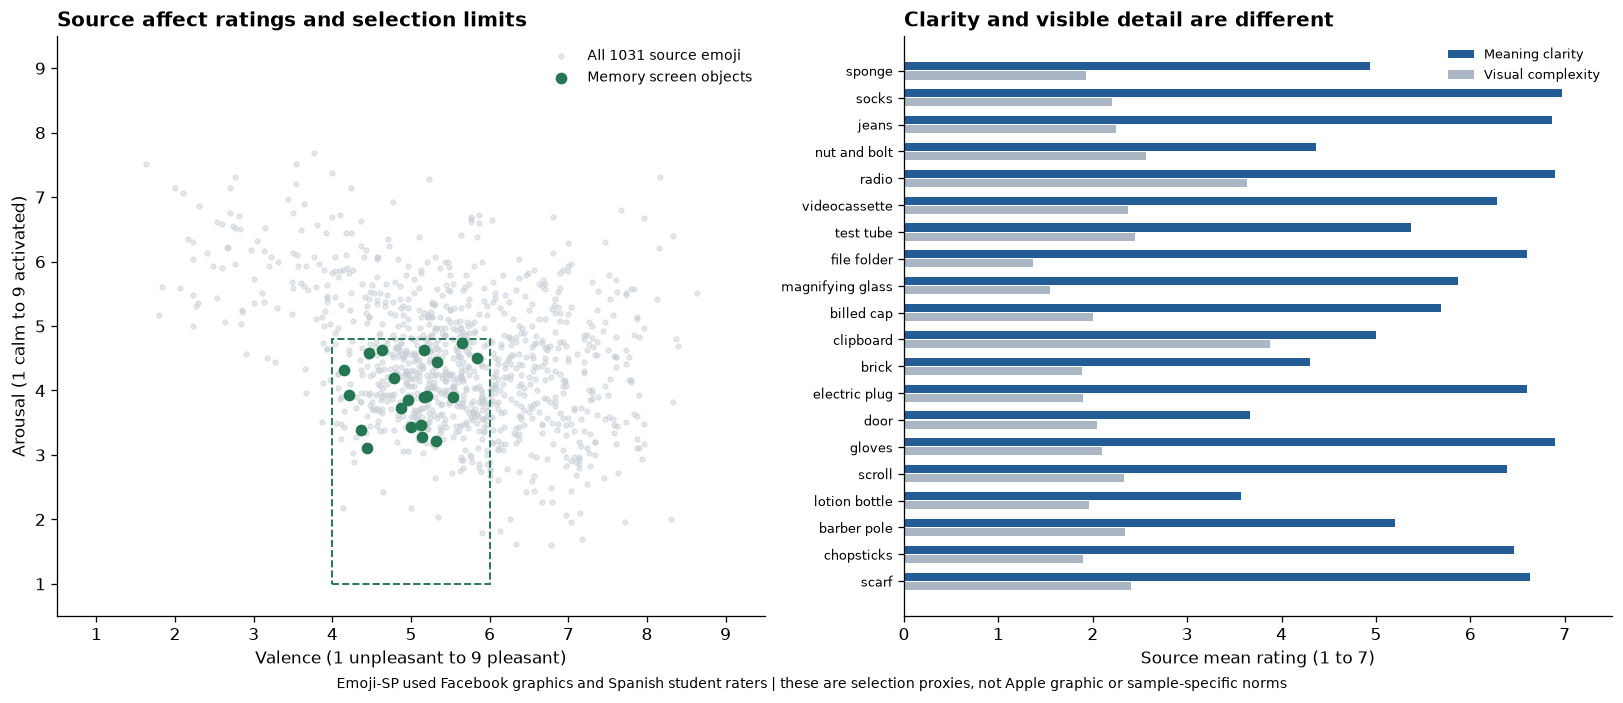

PosixPath('/Users/yizj/Desktop/Desktop - beaverjuly/InCogLab/DroneTask/design_checks/figures/memory_screen/04_affect_and_detail.png')

In [7]:
audit.plot_affect(NORMS, ITEMS)

## Identity and rendering

Encoding, order questions, and this notebook load the same 20 local PNGs, with a common 256 pixel canvas and 192 pixel maximum visible dimension. Operating system emoji fonts therefore cannot alter the item graphics.

Concept checks cover experimental and practice names, documented aliases, Unicode variation selectors, and fallback identities. Byte hashes additionally reject reuse of experimental PNGs. Related broad categories remain, such as clothing versus a coat, folder versus notebook, and test tube versus alembic. Distinct identity does not mean complete semantic unrelatedness.

Each question compares different broad object families. Study order contains no run of three objects from one family. Item and question order vary with the participant seed, independently of the fixed drone geometry. The audit checks 100 seeds.

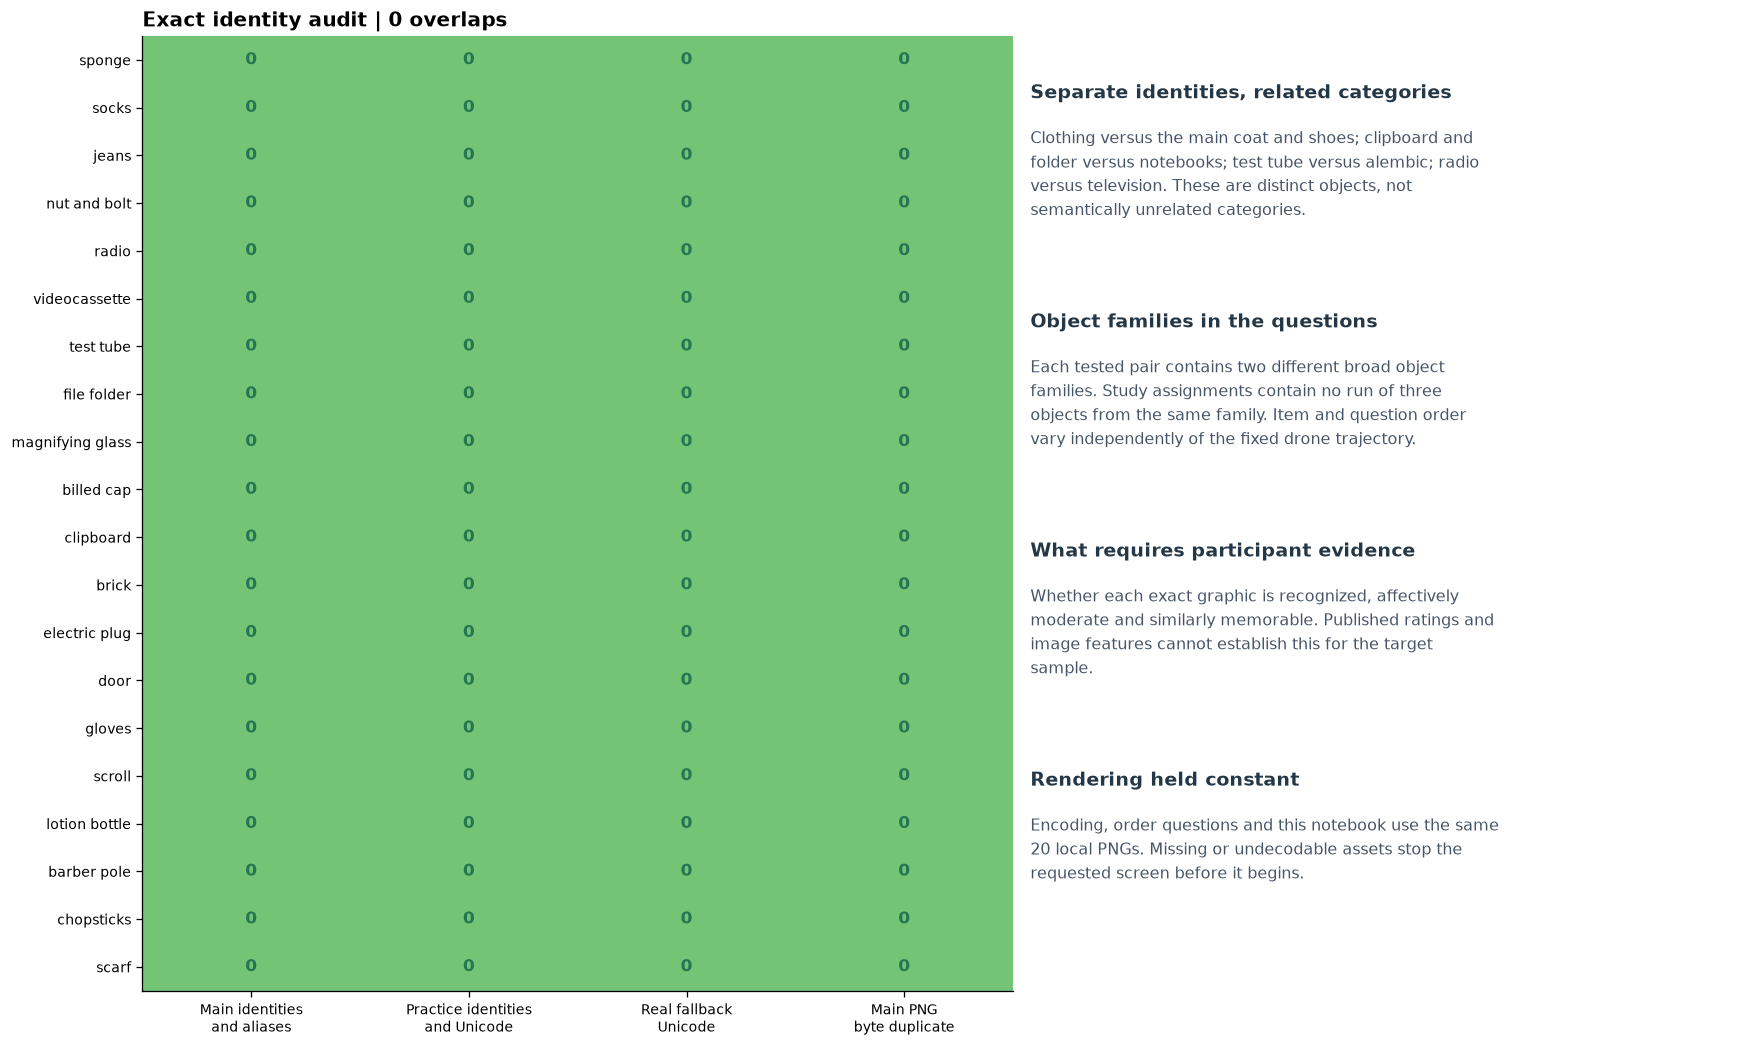

,check,pass,observed
0,20 encoding turns and 10 questions,True,20 / 10
1,Hidden target and zero regime changes,True,hidden / 0
2,Drone hidden in all encoding trials and phase ...,True,"20 hidden trials; phase, entry, and summary me..."
3,Entry instructions describe the hidden drone,True,"<p>On this planet, the <strong>drone will be h..."
4,All 20 shifts have equal displacement,True,20 shifts of 9.05 percentage points
5,Screen mean lies between main volatility groups,True,source high 4.000600 < screen 9.050000 < sourc...
6,Fixed step equals the rounded reference midpoint,True,midpoint 9.049966667; fixed step 9.05
7,Main movement calibration excludes stationary ...,True,15 actual shifts used per block; 34 stationary...
8,Movement calibration metric is saved consistently,True,mean_absolute_nonzero_main_drone_shift
9,Ten shifts left and ten right,True,10 left / 10 right


Main pool 200 Practice pool 13 Fallback pool 39 Normative database 1031


In [8]:
audit.plot_identity(DATA, ITEMS)
display(CHECKS)
print('Main pool',len(DATA['main_pool']), 'Practice pool',len(DATA['practice']),
      'Fallback pool',len(DATA['fallback']), 'Normative database',len(NORMS))

## Order question targets

Every studied object appears in exactly one question. Four pairs have serial gap 2 and six have serial gap 3, meaning one or two intervening objects. The earlier item is shown on the left for five questions and on the right for five, with randomized question order.

The map illustrates the reference seed's study positions, actual left/right presentation, and researcher answer key. These annotations do not appear with participant stimuli. Coverage and side balance do not establish equal pair difficulty.

Responses use Left/Right or 1/2, as in the main order task. Each response has a 5 second window. A timeout gives a 3 second reminder and one further 5 second attempt. A final omission counts incorrect. There is no early stopping, correctness feedback, or retest after a wrong answer.

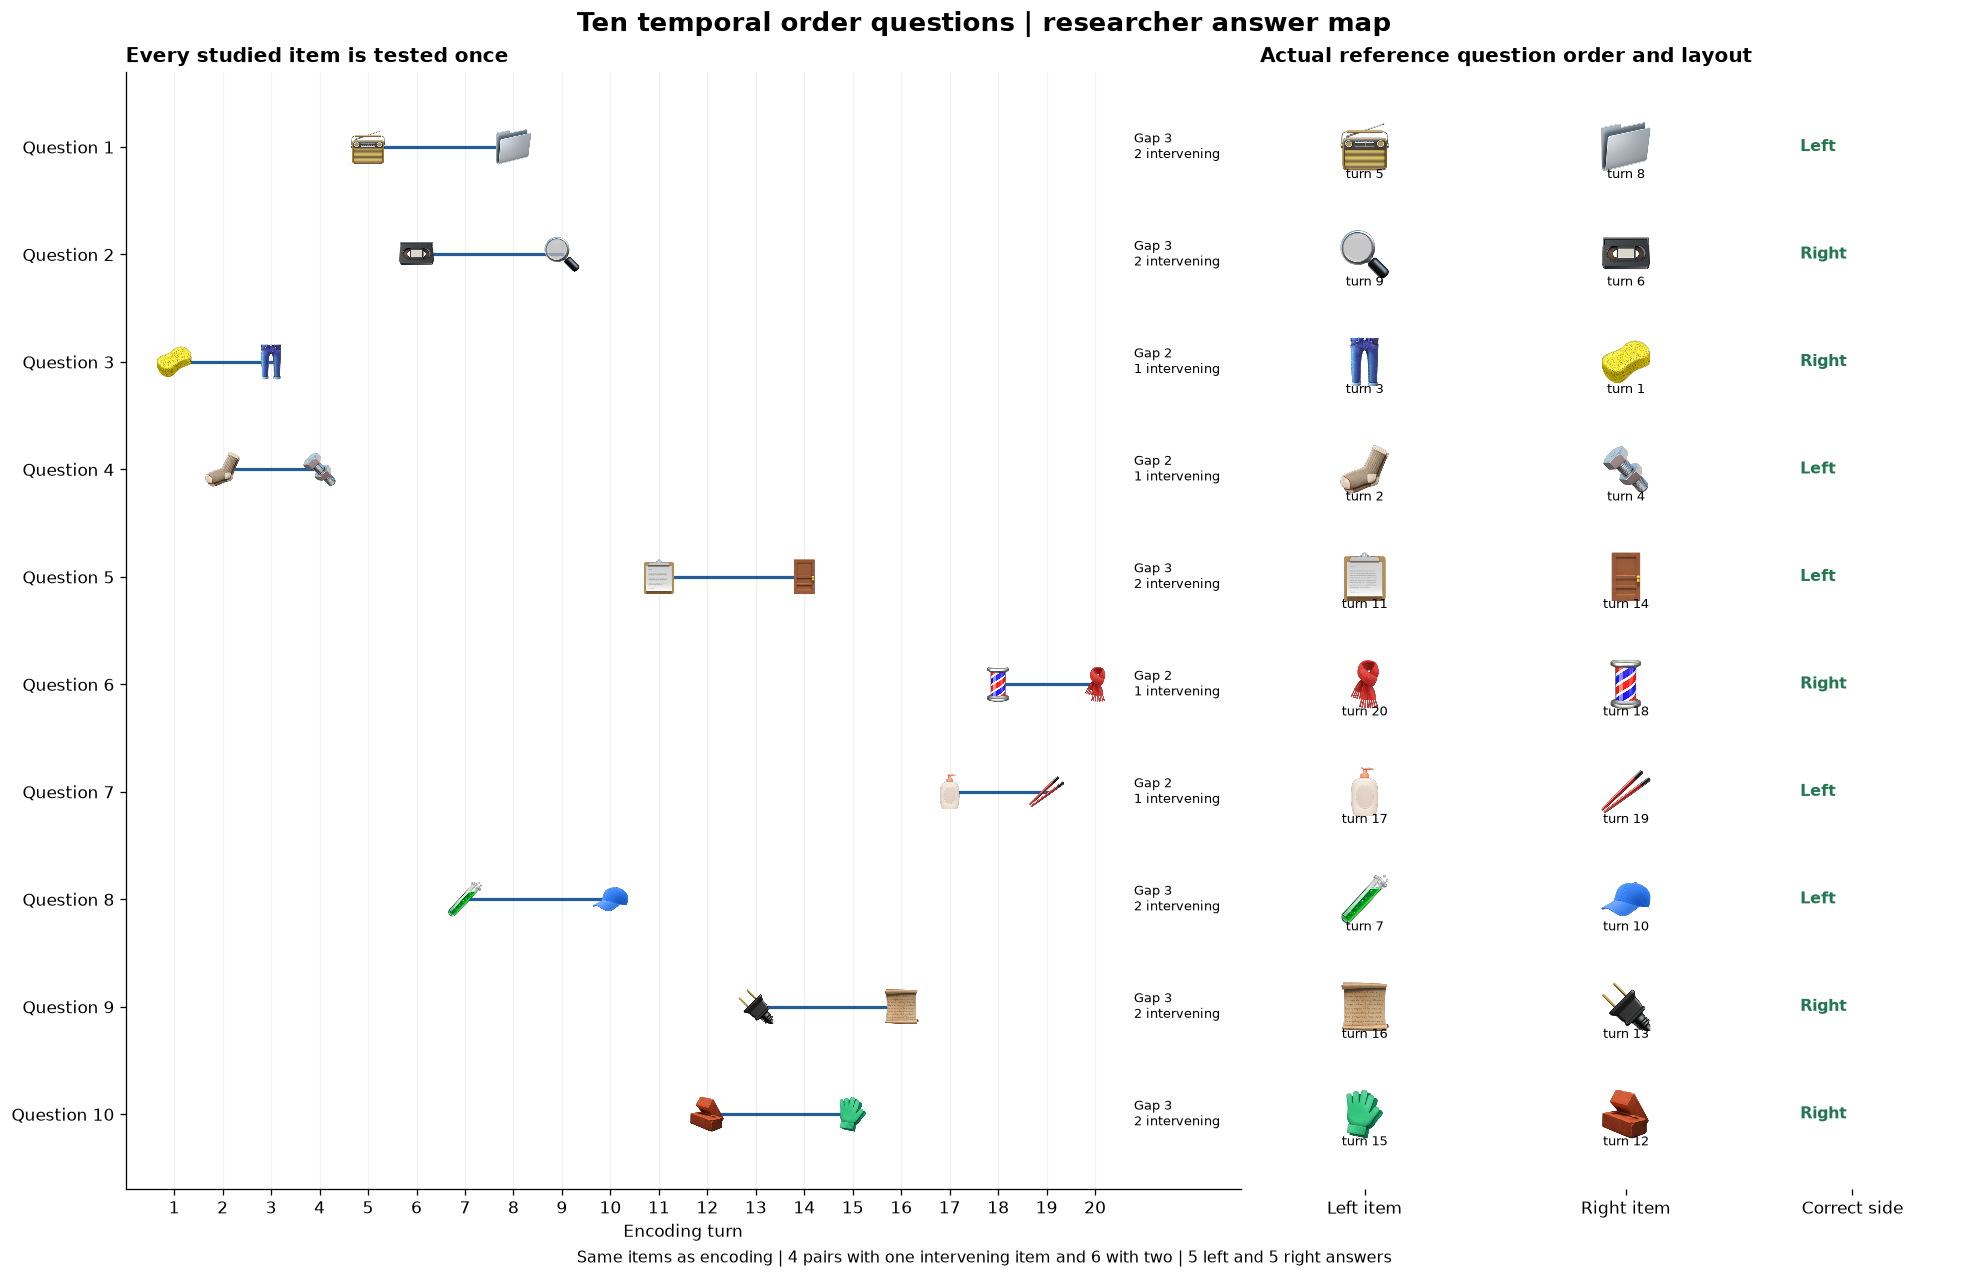

,pair_index,item1_trial,item1_concept,item2_trial,item2_concept,serial_gap,intervening_items,correct_side
0,1,5,radio,8,file-folder,3,2,left
1,2,6,videocassette,9,magnifying-glass,3,2,right
2,3,1,sponge,3,jeans,2,1,right
3,4,2,socks,4,nut-and-bolt,2,1,left
4,5,11,clipboard,14,door,3,2,left
5,6,18,barber-pole,20,scarf,2,1,right
6,7,17,lotion-bottle,19,chopsticks,2,1,left
7,8,7,test-tube,10,billed-cap,3,2,left
8,9,13,electric-plug,16,scroll,3,2,right
9,10,12,brick,15,gloves,3,2,right


In [9]:
audit.plot_pairs(DATA)
PAIRS = pd.DataFrame(SCREEN['pairs'])
PAIRS['serial_gap'] = PAIRS.item2_trial - PAIRS.item1_trial
PAIRS['intervening_items'] = PAIRS.serial_gap - 1
display(PAIRS[['pair_index','item1_trial','item1_concept','item2_trial','item2_concept',
    'serial_gap','intervening_items','correct_side']])

## Selection rule

A complete 20-turn, 10-question screen with at least 6 correct allows continuation. Fewer correct ends through saving. Missing assets or other configuration failures are recorded separately. Interrupted screens retain available rows without a fabricated final outcome.

This rule selects performance on a short-delay order task. It does not isolate a stable memory trait from attention, motor comfort, or strategy. Under independent random guessing, 6 of 10 is reached about 37.7 percent of the time. The following binomial curves are illustrations, not participant estimates. All questions share an encoding episode, so independence need not hold.

Report assigned, technically failed, interrupted, completed, passed, and below-threshold counts separately. Evaluate recognition and pass rates before use, and do not tune the cutoff against the same main-memory outcomes the study will test.

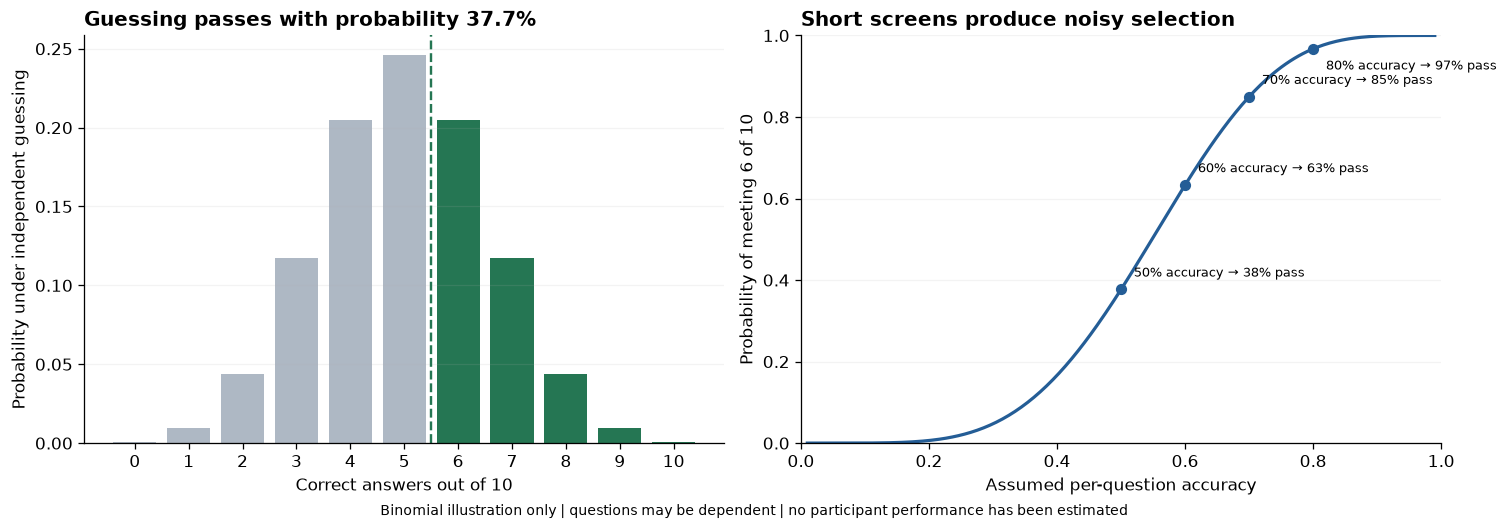

,assumed per-question accuracy,probability of passing 6/10
0,0.5,0.377
1,0.6,0.633
2,0.7,0.850
3,0.8,0.967
4,0.9,0.998


In [10]:
audit.plot_threshold()
from scipy.stats import binom
display(pd.DataFrame({'assumed per-question accuracy':[.5,.6,.7,.8,.9],
    'probability of passing 6/10':binom.sf(5,10,np.array([.5,.6,.7,.8,.9]))}).round(3))

## Routes and outcome handling

Screening is disabled unless `memory_screen=1` is present. Disabled routes do not load the module assets.

| Use | Local route |
|---|---|
| Screen only | [Open module](http://localhost:8000/index.html?dev=1&stage=memory-screen&consent=0&memory_screen=1) |
| Full development with screen | [Open full flow](http://localhost:8000/index.html?dev=1&stage=full&consent=0&memory_screen=1) |
| Full development without screen | [Open core flow](http://localhost:8000/index.html?dev=1&stage=full&consent=0&memory_screen=0) |
| Full local pilot with screen | [Open pilot](http://localhost:8000/index.html?pilot=1&memory_screen=1) |

After deployment, use the same parameters with `https://run.pavlovia.org/jiaheyi/DroneTask/`. Development routes download CSV data locally; pilot routes on Pavlovia save to Pavlovia. The independent mouse switch can be combined with screening through `mouse_qc=1`. See [the URL cheatsheet](../../URLs%20CheatSheet.md).

The screen-only route requires `dev=1` and explicit opt-in, and always stops after its result. An optional `screen_seed` changes item and test assignment only in development. Counts and cutoff cannot be overridden by URL, and no URL can force an outcome.

Requested screening blocks entry if the module, builder, or any image decode fails. It never substitutes another identity or silently starts an unscreened main task. A complete below-threshold session receives a neutral end message and still saves. This outcome does not set bot rejection or use the full study success code. A separate production destination can be configured with `MEMORY_SCREENING_COMPLETION_URL`; the default is blank.

## Data and analysis

Module rows have `memory_screening=true`, `task_phase=memory_screening`, a specific `trial_category`, and block 0. Versioned summaries save trajectory, baseline, constant step size, the nonzero main-movement calibration metric, directions, image assignment, pair assignment, and seed. Encoding rows save completion, start and target position, signed shift, direction, travel duration, and landing offset.

| Split output | Contents |
|---|---|
| `*_memory_screening_encoding.csv` | Initial encoding turns and actual completion/motion data |
| `*_memory_screening_order.csv` | Order responses, serial positions, sides, RT, and timeout history |
| `*_memory_screening_summary.csv` | Outcome, counts, cutoff, versions, and complete assigned material |

The splitter excludes screening from main encoding, memory, and tutorial practice tables. Main analysis independently rejects screening tags. Use [the separate memory screen analysis notebook](../../analysis/memory_screen/memory_screen_analysis.ipynb) for session flow, pass rates, recomputed criteria, item and pair performance, response timing, and motion checks. Screening data are under `analysis/data/memory_screen/`, with separate raw, clean, and derived folders. It does not reinterpret screening as a main-task memory outcome.

## Design checks and exports

This notebook verifies the assigned geometry, direction balance, image identities, rendering, and question coverage against the live source. A live cross-browser preview and deployed Pavlovia saving require separate validation.

The manifest stores both main shift assignments, the reference screen, 100 randomization audits, image hashes, and live source hashes. No participant results are generated by this notebook.

In [11]:
FILES = audit.export_tables(DATA, ITEMS)
for name in FILES:
    print(name)
assert len(list(audit.OUT.glob('*.png'))) == 9
assert CHECKS['pass'].all()
print(f'Completed with {len(CHECKS)} passing design checks and nine exported PNG figures.')

01_trajectory_comparison.png
02_screening_noise.png
03_item_contact_sheet.png
04_affect_and_detail.png
05_order_question_map.png
06_identity_and_selection_audit.png
07_threshold_operating_characteristics.png
08_mean_shift_comparison.png
09_medium_levels.png
automated_checks.csv
design_manifest.json
main_shift_metrics.csv
medium_level_calibration.csv
noise_calibration.csv
order_question_map.csv
selected_item_ratings.csv
shift_calibration.csv
stochasticity_reference.csv
trajectory_metrics.csv
Completed with 37 passing design checks and nine exported PNG figures.
